In [1]:
import gymnasium as gym
import matplotlib.pyplot as plt

In [2]:
env = gym.make("CartPole-v1",render_mode="rgb_array")
obs = env.reset()

In [3]:
obs

(array([-0.00260189,  0.01970963,  0.04989902,  0.01096505], dtype=float32),
 {})

In [4]:
print(list(gym.envs.registry.keys()))

['CartPole-v0', 'CartPole-v1', 'MountainCar-v0', 'MountainCarContinuous-v0', 'Pendulum-v1', 'Acrobot-v1', 'phys2d/CartPole-v0', 'phys2d/CartPole-v1', 'phys2d/Pendulum-v0', 'LunarLander-v3', 'LunarLanderContinuous-v3', 'BipedalWalker-v3', 'BipedalWalkerHardcore-v3', 'CarRacing-v3', 'Blackjack-v1', 'FrozenLake-v1', 'FrozenLake8x8-v1', 'CliffWalking-v1', 'CliffWalkingSlippery-v1', 'Taxi-v3', 'tabular/Blackjack-v0', 'tabular/CliffWalking-v0', 'Reacher-v2', 'Reacher-v4', 'Reacher-v5', 'Pusher-v2', 'Pusher-v4', 'Pusher-v5', 'InvertedPendulum-v2', 'InvertedPendulum-v4', 'InvertedPendulum-v5', 'InvertedDoublePendulum-v2', 'InvertedDoublePendulum-v4', 'InvertedDoublePendulum-v5', 'HalfCheetah-v2', 'HalfCheetah-v3', 'HalfCheetah-v4', 'HalfCheetah-v5', 'Hopper-v2', 'Hopper-v3', 'Hopper-v4', 'Hopper-v5', 'Swimmer-v2', 'Swimmer-v3', 'Swimmer-v4', 'Swimmer-v5', 'Walker2d-v2', 'Walker2d-v3', 'Walker2d-v4', 'Walker2d-v5', 'Ant-v2', 'Ant-v3', 'Ant-v4', 'Ant-v5', 'Humanoid-v2', 'Humanoid-v3', 'Humanoid-

C:\Users\Berkay\Desktop\ML_projects\LSTM_sentiment\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


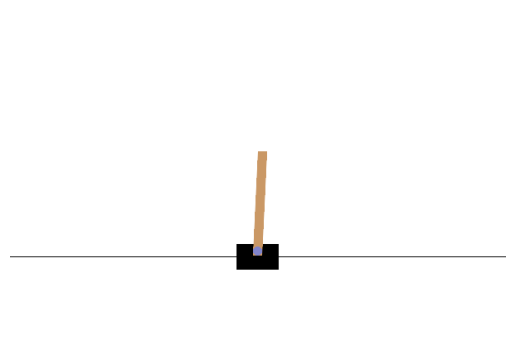

In [5]:
img = env.render()
plt.imshow(img)
plt.axis("off")
plt.show()

In [6]:
env.action_space #actions available

Discrete(2)

In [7]:
action = 1 #go right
obs, reward, terminated, truncated, info = env.step(action)
done = terminated or truncated
obs

array([-0.0022077 ,  0.21408176,  0.05011832, -0.26556602], dtype=float32)

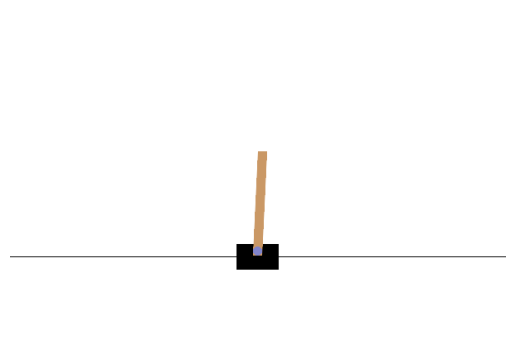

In [8]:
img = env.render()
plt.imshow(img)
plt.axis("off")
plt.show()

In [9]:
reward

1.0

In [10]:
done

False

In [11]:
info

{}

In [12]:
def basic_policy(obs):
    angle = obs[2]
    return 0 if angle < 0 else 1

In [13]:
totals = []
for episode in range(500):
    episode_rewards = 0
    obs, info = env.reset()
    for step in range(200):
        action = basic_policy(obs)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        episode_rewards += reward
        if done:
            break
        totals.append(episode_rewards) 

In [14]:
import numpy as np

np.mean(totals), np.std(totals), np.min(totals), np.max(totals)

(np.float64(21.77103400825634),
 np.float64(13.239477885950508),
 np.float64(1.0),
 np.float64(65.0))

In [15]:
import tensorflow as tf
from tensorflow import keras

n_inputs = 4 #amount of obs available

model = keras.models.Sequential([
    keras.layers.Dense(5, activation="elu", input_shape=[n_inputs]),
    keras.layers.Dense(1, activation="sigmoid"),
])

C:\Users\Berkay\Desktop\ML_projects\LSTM_sentiment\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [16]:
def play_one_step(env,obs,model,loss_fn):
    with tf.GradientTape() as tape:
        left_proba = model(obs[np.newaxis])
        print(left_proba)
        action = (tf.random.uniform([1,1]) > left_proba)
        print(action)
        y_target = tf.constant([[1.]]) - tf.cast(action, tf.float32)
        print(y_target)
        loss = tf.reduce_mean(loss_fn(y_target, left_proba))
        print(loss)
    grads = tape.gradient(loss, model.trainable_variables)
    obs, reward, terminated, truncated, info = env.step(int(action[0, 0].numpy()))
    done = terminated or truncated
    return obs, reward, done, grads

In [17]:
def play_multiple_episodes(env, n_episodes, n_max_steps, model, loss_fn):
    all_rewards = []
    all_grads = []
    for episode in range(n_episodes):
        current_rewards = []
        current_grads = []
        obs, info = env.reset()
        for step in range(n_max_steps):
            obs, reward, done, grads = play_one_step(env, obs, model, loss_fn)
            current_rewards.append(reward)
            current_grads.append(grads)
            if done:
                break
        all_rewards.append(current_rewards)
        all_grads.append(current_grads)
    return all_rewards, all_grads

In [18]:
def discount_rewards(rewards,discount_factor):
    discounted = np.array(rewards)
    for step in range(len(rewards) -2, -1, -1):
        discounted[step] += discounted[step+1] * discount_factor
        return discounted

In [19]:
def discount_and_normalize_rewards(all_rewards, discount_factor):
    all_discounted_rewards = [discount_rewards(rewards, discount_factor)
                              for rewards in all_rewards]
    flat_rewards = np.concatenate(all_discounted_rewards)
    reward_mean = flat_rewards.mean()
    reward_std = flat_rewards.std()
    return [(discounted_rewards - reward_mean) / reward_std
            for discounted_rewards in all_discounted_rewards]

In [20]:
n_iterations = 150
n_episodes_per_update = 10
n_max_steps = 200
discount_factor = 0.95

optimizer = keras.optimizers.Adam()
loss_fn = keras.losses.binary_crossentropy

In [21]:
for iteration in range(n_iterations):
    all_rewards, all_grads = play_multiple_episodes(
        env, n_episodes_per_update, n_max_steps, model, loss_fn)
    total_rewards = sum(map(sum, all_rewards))
    print(f"Iteration {iteration + 1}/{n_iterations}, mean rewards: {total_rewards / n_episodes_per_update:.1f}")

    all_final_rewards = discount_and_normalize_rewards(all_rewards, discount_factor)
    all_mean_grads = []
    for var_index in range(len(model.trainable_variables)):
        mean_grads = tf.reduce_mean(
            [final_reward * all_grads[episode_index][step][var_index]
             for episode_index, final_rewards in enumerate(all_final_rewards)
             for step, final_reward in enumerate(final_rewards)], axis=0)
        all_mean_grads.append(mean_grads)
    optimizer.apply_gradients(zip(all_mean_grads, model.trainable_variables))

tf.Tensor([[0.50676084]], shape=(1, 1), dtype=float32)
tf.Tensor([[False]], shape=(1, 1), dtype=bool)
tf.Tensor([[1.]], shape=(1, 1), dtype=float32)
tf.Tensor(0.6797161, shape=(), dtype=float32)
tf.Tensor([[0.55370986]], shape=(1, 1), dtype=float32)
tf.Tensor([[ True]], shape=(1, 1), dtype=bool)
tf.Tensor([[0.]], shape=(1, 1), dtype=float32)
tf.Tensor(0.8067859, shape=(), dtype=float32)
tf.Tensor([[0.5047042]], shape=(1, 1), dtype=float32)
tf.Tensor([[False]], shape=(1, 1), dtype=bool)
tf.Tensor([[1.]], shape=(1, 1), dtype=float32)
tf.Tensor(0.6837828, shape=(), dtype=float32)
tf.Tensor([[0.55222124]], shape=(1, 1), dtype=float32)
tf.Tensor([[False]], shape=(1, 1), dtype=bool)
tf.Tensor([[1.]], shape=(1, 1), dtype=float32)
tf.Tensor(0.5938066, shape=(), dtype=float32)
tf.Tensor([[0.5987216]], shape=(1, 1), dtype=float32)
tf.Tensor([[ True]], shape=(1, 1), dtype=bool)
tf.Tensor([[0.]], shape=(1, 1), dtype=float32)
tf.Tensor(0.9130999, shape=(), dtype=float32)
tf.Tensor([[0.5533263]], sh

In [22]:
import numpy as np

env = gym.make("CartPole-v0")
input_shape = [4]
n_outputs = 2

model = keras.models.Sequential([
    keras.layers.Dense(32, activation="elu", input_shape=input_shape),
    keras.layers.Dense(32, activation="elu"),
    keras.layers.Dense(n_outputs)])

C:\Users\Berkay\Desktop\ML_projects\LSTM_sentiment\Lib\site-packages\gymnasium\envs\registration.py:512: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


In [23]:
def epsilon_greedy_policy(state, epsilon=0):
    if np.random.rand() < epsilon: #epsilon controls how often to try a random action instead of picking the best one
        return np.random.randint(2)
    else:
        Q_values = model.predict(state[np.newaxis])#make a prediction for all states
        return np.argmax(Q_values[0])#return Q value

In [24]:
from collections import deque

replay_buffer = deque(maxlen=20000)

In [25]:
def sample_experiences(batch_size):
    indices = np.random.randint(len(replay_buffer), size=batch_size) #pick a random position in the replay buffer 
    batch = [replay_buffer[index] for index in indices] #fetch old attempts
    states, actions, rewards, next_states, dones = [
        np.array([experience[field_index] for experience in batch])
        for field_index in range(5)] #Separate each attempt into five piles
    return states, actions, rewards, next_states, dones

In [26]:
def play_one_step(env, state, epsilon):
    action = epsilon_greedy_policy(state, epsilon)
    next_state, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated

    replay_buffer.append((state, action, reward, next_state, done))
    return next_state, reward, done, info

In [27]:
batch_size = 32
discount_factor = 0.95
optimizer = keras.optimizers.Adam()
loss_fn = keras.losses.MeanSquaredError()

In [28]:
def training_step(batch_size):
    experiences = sample_experiences(batch_size)
    states,actions,rewards, next_states, dones = experiences
    next_Q_values = model.predict(next_states)
    max_next_Q_values = np.max(next_Q_values, axis=1)
    target_Q_values = (rewards +
    (1-dones) * discount_factor * max_next_Q_values)
    mask = tf.one_hot(actions, n_outputs)
    with tf.GradientTape() as tape:
        all_Q_values = model(states)
        Q_values = tf.reduce_sum(all_Q_values * mask, axis=1, keepdims=True)
        loss = tf.reduce_mean(loss_fn(target_Q_values, Q_values))
    grads = tape.gradient(loss,model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

In [32]:
# replay_buffer.clear()

# for episode in range(500):
#     obs, info = env.reset()
#     for step in range(200):
#         epsilon = max(1- episode/ 500, 0.01)
#         obs, reward, done, info = play_one_step(env, obs, epsilon)
#         if done:
#             break
#     if episode > 50:
#         training_step(batch_size)

In [33]:
target = keras.models.clone_model(model)
target.set_weights(model.get_weights())

In [39]:
# next_Q_values = target.predict(next_states)

In [38]:
# if episode % 50 == 0:
#     target.set_weights(model.get_weights())